# Лабораторна робота №8
## Тема: Самостійне моделювання на даних із зовнішніх джерел

### Варіант 10 — Dry Bean Dataset

### Мета роботи
Навчитися отримувати та перевіряти зовнішні табличні дані,
готувати ознаки, навчати й оцінювати нейромережу для
багатокласової класифікації.

## Імпорт бібліотек ##

In [1]:
import os
import json
import random
import warnings
import platform
import sklearn
import matplotlib
import joblib
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)

from joblib import dump, load

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Для відтворюваності результатів
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

print("SEED:", SEED)

Python: 3.12.5
NumPy: 2.5.3
Pandas: 3.0.6
TensorFlow: 2.21.0
SEED: 42


## Створення структури папок ##

In [2]:
DATA_DIR = Path("data")
ARTIFACTS_DIR = Path("artifacts")
FIGURES_DIR = Path("figures")

DATA_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

(ARTIFACTS_DIR / "checkpoints").mkdir(exist_ok=True)

file_path = DATA_DIR / "Dry_Bean_Dataset.xlsx"

print("Файл існує:", file_path.exists())
print("Шлях до файлу:", file_path)

Файл існує: True
Шлях до файлу: data\Dry_Bean_Dataset.xlsx


## Перевірка Excel-файлу та назви аркуша ##

In [3]:
excel = pd.ExcelFile(file_path)

print("Доступні аркуші:", excel.sheet_names)

Доступні аркуші: ['Dry_Beans_Dataset', 'Citation_Request']


## Паспорт ##

In [4]:
dataset_info = {
    "dataset_name": "Dry Bean Dataset",
    "source": "UCI Machine Learning Repository",
    "url": "https://archive.ics.uci.edu/dataset/602/dry+bean+dataset",
    "authors": [
        "Murat Koklu",
        "Ilker Ali Ozkan"
    ],
    "year": 2020,
    "license": "CC BY 4.0",
    "doi": "10.24432/C50S4B",
    "download_date": str(date.today()),
    "file": "Dry_Bean_Dataset.xlsx",
    "sheet": "Dry_Beans_Dataset",
    "records_expected": 13611,
    "features_expected": 16,
    "target": "Class",
    "target_units": "Назви сортів квасолі, одиниці вимірювання відсутні",
    "seed": SEED
}

with open(ARTIFACTS_DIR / "dataset_info.json", "w",
          encoding="utf-8") as f:
    json.dump(dataset_info, f, ensure_ascii=False, indent=4)

print(json.dumps(dataset_info, ensure_ascii=False, indent=4))

{
    "dataset_name": "Dry Bean Dataset",
    "source": "UCI Machine Learning Repository",
    "url": "https://archive.ics.uci.edu/dataset/602/dry+bean+dataset",
    "authors": [
        "Murat Koklu",
        "Ilker Ali Ozkan"
    ],
    "year": 2020,
    "license": "CC BY 4.0",
    "doi": "10.24432/C50S4B",
    "download_date": "2026-11-10",
    "file": "Dry_Bean_Dataset.xlsx",
    "sheet": "Dry_Beans_Dataset",
    "records_expected": 13611,
    "features_expected": 16,
    "target": "Class",
    "target_units": "Назви сортів квасолі, одиниці вимірювання відсутні",
    "seed": 42
}


## Завантаження даних ##

In [5]:
df = pd.read_excel(file_path)

print("Дані успішно завантажено.")

Дані успішно завантажено.


In [7]:
#Перегляд перших рядків
display(df.head())

#Перевірка розмірності
print("Кількість рядків і стовпців:", df.shape)
print("Кількість рядків:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

#Перевірка типів даних
df.info()

print("\nТипи даних:")
print(df.dtypes)

#Статистичний опис
display(df.describe())

#Перевірка пропущених значень
print("Кількість пропущених значень:")
print(df.isnull().sum())

print("\nЗагальна кількість пропусків:", df.isnull().sum().sum())

#Виявлення дублікатів
duplicate_rows = df[df.duplicated(keep=False)]

print("Кількість рядків, які мають повні дублікати:", len(duplicate_rows))

print("\nДублікати за класами:")
print(duplicate_rows["Class"].value_counts())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Кількість рядків і стовпців: (13611, 17)
Кількість рядків: 13611
Кількість стовпців: 17
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


Кількість пропущених значень:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Загальна кількість пропусків: 0
Кількість рядків, які мають повні дублікати: 136

Дублікати за класами:
Class
HOROZ    136
Name: count, dtype: int64


## Видалення повних дублікатів ##

In [8]:
print("Кількість дублікатів для видалення:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Розмірність після видалення дублікатів:", df.shape)
print("Дублікатів після очищення:", df.duplicated().sum())

Кількість дублікатів для видалення: 68
Розмірність після видалення дублікатів: (13543, 17)
Дублікатів після очищення: 0


## Визначення ознак і цільової змінної ##

In [9]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

print("\nОзнаки:")
print(X.columns.tolist())

print("\nЦільова змінна:", y.name)

Розмір X: (13543, 16)
Розмір y: (13543,)

Ознаки:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Цільова змінна: Class


## Визначення класів ##

In [10]:
classes = sorted(y.unique())

print("Кількість класів:", len(classes))
print("Назви класів:", classes)

print("\nКількість об'єктів кожного класу:")
print(y.value_counts().sort_index())

Кількість класів: 7
Назви класів: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Кількість об'єктів кожного класу:
Class
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1860
SEKER       2027
SIRA        2636
Name: count, dtype: int64


## Визначення типів ознак ##

In [11]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Числові ознаки:", numeric_features)
print("Категоріальні ознаки:", categorical_features)

Числові ознаки: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Категоріальні ознаки: []


## Поділ на навчальну, валідаційну та тестову вибірки ##

In [12]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=y_train_val
)

print("Навчальна вибірка:", X_train.shape)
print("Валідаційна вибірка:", X_val.shape)
print("Тестова вибірка:", X_test.shape)

print("\nЗагальна кількість:", 
      len(X_train) + len(X_val) + len(X_test))

Навчальна вибірка: (9479, 16)
Валідаційна вибірка: (2032, 16)
Тестова вибірка: (2032, 16)

Загальна кількість: 13543


## Перевірка часток вибірок ##

In [13]:
total = len(X)

print("Train:", len(X_train) / total)
print("Validation:", len(X_val) / total)
print("Test:", len(X_test) / total)

Train: 0.6999187772280883
Validation: 0.15004061138595584
Test: 0.15004061138595584


## Перевірка відсутності перетину між вибірками ##

In [14]:
train_indices = set(X_train.index)
val_indices = set(X_val.index)
test_indices = set(X_test.index)

print("Train ∩ Validation:", len(train_indices & val_indices))
print("Train ∩ Test:", len(train_indices & test_indices))
print("Validation ∩ Test:", len(val_indices & test_indices))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


## Збереження індексів вибірок ##

In [15]:
split_indices = {
    "train": X_train.index.tolist(),
    "validation": X_val.index.tolist(),
    "test": X_test.index.tolist()
}

np.savez(
    ARTIFACTS_DIR / "split_indices.npz",
    train=np.array(split_indices["train"]),
    validation=np.array(split_indices["validation"]),
    test=np.array(split_indices["test"])
)

print("Індекси всіх вибірок збережено.")

Індекси всіх вибірок збережено.


## Створення конвеєра попередньої обробки ##

In [16]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

transformers = [
    ("num", numeric_transformer, numeric_features)
]

if categorical_features:
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    transformers.append(
        ("cat", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

## Навчання обробника лише на навчальних даних ##

In [17]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

## Перетворення даних у формат float32 ##

In [18]:
X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (9479, 16)
Validation: (2032, 16)
Test: (2032, 16)


## Перевірка пропущених та нескінченних значень ##

In [19]:
for name, arr in [
    ("Train", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed)
]:
    print(f"\n{name}:")
    print("NaN:", np.isnan(arr).sum())
    print("Infinity:", np.isinf(arr).sum())


Train:
NaN: 0
Infinity: 0

Validation:
NaN: 0
Infinity: 0

Test:
NaN: 0
Infinity: 0


## Кодування цільових класів ##

In [20]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

class_names = label_encoder.classes_

print("Кодування класів:")

for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

Кодування класів:
0 -> BARBUNYA
1 -> BOMBAY
2 -> CALI
3 -> DERMASON
4 -> HOROZ
5 -> SEKER
6 -> SIRA


## Створення та навчання DummyClassifier ##

In [21]:
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train_processed, y_train_encoded)

dummy_val_pred = dummy_model.predict(X_val_processed)

dummy_val_accuracy = accuracy_score(
    y_val_encoded, dummy_val_pred
)

dummy_val_f1 = f1_score(
    y_val_encoded,
    dummy_val_pred,
    average="macro"
)

print("Dummy Accuracy:", dummy_val_accuracy)
print("Dummy Macro-F1:", dummy_val_f1)

Dummy Accuracy: 0.2618110236220472
Dummy Macro-F1: 0.059282371294851796


## Створення та навчання Logistic Regression ##

In [22]:
logreg_model = LogisticRegression(max_iter=2000)

logreg_model.fit(X_train_processed, y_train_encoded)

logreg_val_pred = logreg_model.predict(X_val_processed)

logreg_val_accuracy = accuracy_score(
    y_val_encoded, logreg_val_pred
)

logreg_val_f1 = f1_score(
    y_val_encoded,
    logreg_val_pred,
    average="macro"
)

print("Logistic Regression Accuracy:", logreg_val_accuracy)
print("Logistic Regression Macro-F1:", logreg_val_f1)

Logistic Regression Accuracy: 0.922736220472441
Logistic Regression Macro-F1: 0.9315416188423767


## Створення базової нейронної мережі NN_base ##

In [23]:
def build_nn_base(input_dim, num_classes):

    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    return model

## Налаштування навчання та контрольних точок ##

In [24]:
checkpoint_base = ARTIFACTS_DIR / "checkpoints" / "nn_base_best.keras"

callbacks_base = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_base,
        monitor="val_loss",
        save_best_only=True
    )
]

## Навчання NN_base ##

In [25]:
tf.keras.utils.set_random_seed(SEED)

nn_base = build_nn_base(
    X_train_processed.shape[1],
    len(class_names)
)

history_base = nn_base.fit(
    X_train_processed,
    y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=200,
    batch_size=64,
    callbacks=callbacks_base,
    verbose=1
)

Epoch 1/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6802 - loss: 0.9898 - val_accuracy: 0.8420 - val_loss: 0.4900
Epoch 2/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8931 - loss: 0.3535 - val_accuracy: 0.9045 - val_loss: 0.2913
Epoch 3/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9159 - loss: 0.2502 - val_accuracy: 0.9124 - val_loss: 0.2469
Epoch 4/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9193 - loss: 0.2241 - val_accuracy: 0.9163 - val_loss: 0.2320
Epoch 5/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9221 - loss: 0.2133 - val_accuracy: 0.9188 - val_loss: 0.2242
Epoch 6/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9248 - loss: 0.2071 - val_accuracy: 0.9218 - val_loss: 0.2183
Epoch 7/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9264 - loss: 0.2026 - val_accuracy: 0.9237 - val_loss: 0.2140
Epoch 8/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9273 - loss: 0.1989 - val_accu

## Завантаження найкращого контрольного стану ##

In [26]:
nn_base = keras.models.load_model(checkpoint_base)

best_epoch_base = np.argmin(
    history_base.history["val_loss"]
) + 1

print("Найкраща епоха NN_base:", best_epoch_base)

Найкраща епоха NN_base: 74


## Оцінювання NN_base на валідаційній вибірці ##

In [27]:
base_val_loss, base_val_accuracy = nn_base.evaluate(
    X_val_processed,
    y_val_encoded,
    verbose=0
)

base_val_prob = nn_base.predict(
    X_val_processed,
    verbose=0
)

base_val_pred = np.argmax(base_val_prob, axis=1)

base_val_f1 = f1_score(
    y_val_encoded,
    base_val_pred,
    average="macro"
)

print("NN_base Validation Loss:", base_val_loss)
print("NN_base Accuracy:", base_val_accuracy)
print("NN_base Macro-F1:", base_val_f1)

NN_base Validation Loss: 0.19230087101459503
NN_base Accuracy: 0.9227362275123596
NN_base Macro-F1: 0.9346111451649638


## Формулювання гіпотези ##
Перевіряємо, чи покращиться якість нейронної мережі, якщо зменшити швидкість навчання з 0.001 до 0.0003.

## Створення покращеної нейронної мережі NN_improved ##

In [28]:
def build_nn_improved(input_dim, num_classes):

    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.0003
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    return model

## Налаштування контрольних точок ##

In [29]:
checkpoint_improved = (
    ARTIFACTS_DIR / "checkpoints" / "nn_improved_best.keras"
)

callbacks_improved = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_improved,
        monitor="val_loss",
        save_best_only=True
    )
]

## Навчання NN_improved ##

In [30]:
tf.keras.utils.set_random_seed(SEED)

nn_improved = build_nn_improved(
    X_train_processed.shape[1],
    len(class_names)
)

history_improved = nn_improved.fit(
    X_train_processed,
    y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=200,
    batch_size=64,
    callbacks=callbacks_improved,
    verbose=1
)

Epoch 1/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4633 - loss: 1.5330 - val_accuracy: 0.6969 - val_loss: 1.1526
Epoch 2/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7505 - loss: 0.9135 - val_accuracy: 0.7751 - val_loss: 0.7265
Epoch 3/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8308 - loss: 0.6069 - val_accuracy: 0.8430 - val_loss: 0.5171
Epoch 4/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8755 - loss: 0.4470 - val_accuracy: 0.8809 - val_loss: 0.4027
Epoch 5/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8976 - loss: 0.3577 - val_accuracy: 0.8981 - val_loss: 0.3379
Epoch 6/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9049 - loss: 0.3055 - val_accuracy: 0.9050 - val_loss: 0.2989
Epoch 7/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9103 - loss: 0.2732 - val_accuracy: 0.9109 - val_loss: 0.2742
Epoch 8/200
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9152 - loss: 0.2528 - val_accu

## Завантаження найкращого стану NN_improved ##

In [31]:
nn_improved = keras.models.load_model(checkpoint_improved)

best_epoch_improved = np.argmin(
    history_improved.history["val_loss"]
) + 1

print("Найкраща епоха NN_improved:", best_epoch_improved)

Найкраща епоха NN_improved: 200


## Оцінювання NN_improved ##

In [32]:
improved_val_loss, improved_val_accuracy = nn_improved.evaluate(
    X_val_processed,
    y_val_encoded,
    verbose=0
)

improved_val_prob = nn_improved.predict(
    X_val_processed,
    verbose=0
)

improved_val_pred = np.argmax(improved_val_prob, axis=1)

improved_val_f1 = f1_score(
    y_val_encoded,
    improved_val_pred,
    average="macro"
)

print("NN_improved Validation Loss:", improved_val_loss)
print("NN_improved Accuracy:", improved_val_accuracy)
print("NN_improved Macro-F1:", improved_val_f1)

NN_improved Validation Loss: 0.1894877403974533
NN_improved Accuracy: 0.9276574850082397
NN_improved Macro-F1: 0.93803573665838


## Порівняльна таблиця результатів на валідації ##

In [33]:
validation_results = pd.DataFrame([
    {
        "Model": "DummyClassifier",
        "Accuracy": dummy_val_accuracy,
        "Macro-F1": dummy_val_f1,
        "Validation_CrossEntropy": np.nan
    },
    {
        "Model": "LogisticRegression",
        "Accuracy": logreg_val_accuracy,
        "Macro-F1": logreg_val_f1,
        "Validation_CrossEntropy": np.nan
    },
    {
        "Model": "NN_base",
        "Accuracy": base_val_accuracy,
        "Macro-F1": base_val_f1,
        "Validation_CrossEntropy": base_val_loss
    },
    {
        "Model": "NN_improved",
        "Accuracy": improved_val_accuracy,
        "Macro-F1": improved_val_f1,
        "Validation_CrossEntropy": improved_val_loss
    }
])

display(
    validation_results.sort_values(
        by="Macro-F1",
        ascending=False
    )
)

,Model,Accuracy,Macro-F1,Validation_CrossEntropy
3,NN_improved,0.927657,0.938036,0.189488
2,NN_base,0.922736,0.934611,0.192301
1,LogisticRegression,0.922736,0.931542,NaN
0,DummyClassifier,0.261811,0.059282,NaN


## Вибір найкращої моделі загалом ##

In [34]:
best_model_name = validation_results.loc[
    validation_results["Macro-F1"].idxmax(),
    "Model"
]

best_validation_f1 = validation_results["Macro-F1"].max()

print("Найкраща модель:", best_model_name)
print("Найкращий Validation Macro-F1:", best_validation_f1)

Найкраща модель: NN_improved
Найкращий Validation Macro-F1: 0.93803573665838


## Окремий вибір найкращої нейронної мережі ##

In [35]:
if improved_val_f1 > base_val_f1:
    best_nn_name = "NN_improved"
    best_nn = nn_improved
    best_nn_epoch = best_epoch_improved
else:
    best_nn_name = "NN_base"
    best_nn = nn_base
    best_nn_epoch = best_epoch_base

print("Найкраща нейронна мережа:", best_nn_name)
print("Найкраща епоха:", best_nn_epoch)

Найкраща нейронна мережа: NN_improved
Найкраща епоха: 200


## Побудова графіків навчання обох нейронних мереж ##

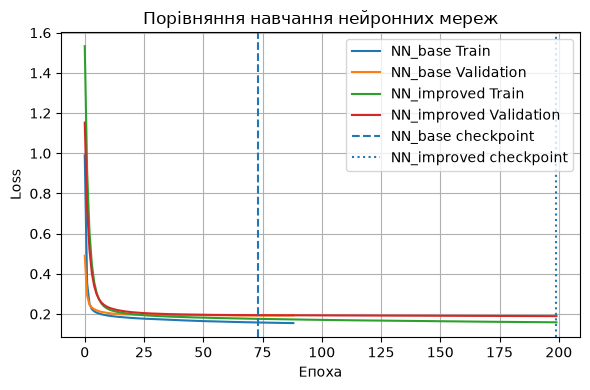

In [36]:
plt.figure(figsize=(6, 4))

plt.plot(history_base.history["loss"], label="NN_base Train")
plt.plot(history_base.history["val_loss"], label="NN_base Validation")

plt.plot(history_improved.history["loss"], label="NN_improved Train")
plt.plot(history_improved.history["val_loss"], label="NN_improved Validation")

plt.axvline(
    best_epoch_base - 1,
    linestyle="--",
    label="NN_base checkpoint"
)

plt.axvline(
    best_epoch_improved - 1,
    linestyle=":",
    label="NN_improved checkpoint"
)

plt.title("Порівняння навчання нейронних мереж")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_training_curves.png",
    dpi=300
)

plt.show()

## Побудова розподілу класів навчальної вибірки ##

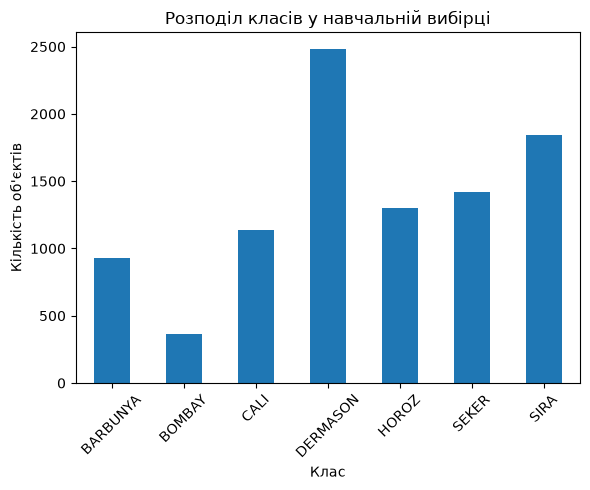

In [37]:
plt.figure(figsize=(6, 5))

y_train.value_counts().sort_index().plot(kind="bar")

plt.title("Розподіл класів у навчальній вибірці")
plt.xlabel("Клас")
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "01_train_class_distribution.png", dpi=300)

plt.show()

## Створення списку всіх моделей ##

In [38]:
models = {
    "DummyClassifier": dummy_model,
    "LogisticRegression": logreg_model,
    "NN_base": nn_base,
    "NN_improved": nn_improved
}

## Оцінювання всіх моделей на тестовій вибірці ##

In [39]:
test_results = []

test_predictions = {}
test_probabilities = {}

for name, model in models.items():

    if name in ["NN_base", "NN_improved"]:
        probabilities = model.predict(
            X_test_processed,
            verbose=0
        )
        predictions = np.argmax(probabilities, axis=1)
        test_loss = log_loss(
            y_test_encoded,
            probabilities,
            labels=np.arange(len(class_names))
        )
        best_epoch = (
            best_epoch_base if name == "NN_base"
            else best_epoch_improved
        )

    else:
        predictions = model.predict(X_test_processed)
        probabilities = model.predict_proba(X_test_processed)
        test_loss = log_loss(
            y_test_encoded,
            probabilities,
            labels=np.arange(len(class_names))
        )
        best_epoch = None

    test_predictions[name] = predictions
    test_probabilities[name] = probabilities

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_encoded, predictions),
        "Precision_macro": precision_score(
            y_test_encoded, predictions,
            average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_test_encoded, predictions,
            average="macro", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_test_encoded, predictions,
            average="macro", zero_division=0
        ),
        "Test_CrossEntropy": test_loss,
        "Best_epoch": best_epoch
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df)

,Model,Accuracy,Precision_macro,Recall_macro,Macro-F1,Test_CrossEntropy,Best_epoch
0,DummyClassifier,0.261811,0.037402,0.142857,0.059282,26.607028,NaN
1,LogisticRegression,0.916831,0.929427,0.929955,0.929599,0.228287,NaN
2,NN_base,0.924705,0.935888,0.933802,0.934675,0.216539,74.0
3,NN_improved,0.924705,0.935560,0.936118,0.935759,0.214730,200.0


## Створення порівняльної таблиці моделей ##

In [40]:
comparison_df = validation_results.merge(
    test_results_df,
    on="Model"
)

comparison_df["Validation_criterion"] = "Macro-F1"

comparison_df["Change"] = [
    "Baseline",
    "Baseline",
    "NN_base",
    "Learning rate: 0.0003"
]

comparison_df["Training_samples"] = len(X_train)

comparison_df.to_csv(
    ARTIFACTS_DIR / "model_comparison.csv",
    index=False
)

display(comparison_df)

,Model,Accuracy_x,Macro-F1_x,Validation_CrossEntropy,Accuracy_y,Precision_macro,Recall_macro,Macro-F1_y,Test_CrossEntropy,Best_epoch,Validation_criterion,Change,Training_samples
0,DummyClassifier,0.261811,0.059282,NaN,0.261811,0.037402,0.142857,0.059282,26.607028,NaN,Macro-F1,Baseline,9479
1,LogisticRegression,0.922736,0.931542,NaN,0.916831,0.929427,0.929955,0.929599,0.228287,NaN,Macro-F1,Baseline,9479
2,NN_base,0.922736,0.934611,0.192301,0.924705,0.935888,0.933802,0.934675,0.216539,74.0,Macro-F1,NN_base,9479
3,NN_improved,0.927657,0.938036,0.189488,0.924705,0.935560,0.936118,0.935759,0.214730,200.0,Macro-F1,Learning rate: 0.0003,9479


## Визначення найкращої нейронної мережі на тесті ##

In [41]:
best_nn_predictions = test_predictions[best_nn_name]

print(classification_report(
    y_test_encoded,
    best_nn_predictions,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.91      0.92       198
      BOMBAY       1.00      1.00      1.00        78
        CALI       0.92      0.95      0.93       245
    DERMASON       0.92      0.92      0.92       532
       HOROZ       0.97      0.95      0.96       279
       SEKER       0.94      0.96      0.95       304
        SIRA       0.88      0.86      0.87       396

    accuracy                           0.92      2032
   macro avg       0.94      0.94      0.94      2032
weighted avg       0.92      0.92      0.92      2032



## Побудова матриці помилок ##

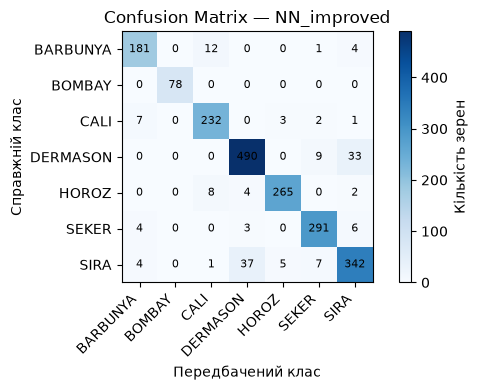

In [42]:
cm = confusion_matrix(
    y_test_encoded,
    best_nn_predictions
)

plt.figure(figsize=(6, 4))

plt.imshow(cm, cmap="Blues")
plt.colorbar(label="Кількість зерен")

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

# Підписуємо клітинки значеннями
for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            fontsize=8
        )

plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.title(f"Confusion Matrix — {best_nn_name}")

plt.tight_layout()

plt.savefig(FIGURES_DIR / "03_confusion_matrix.png", dpi=300)

plt.show()

## Побудова F1-score для кожного класу ##

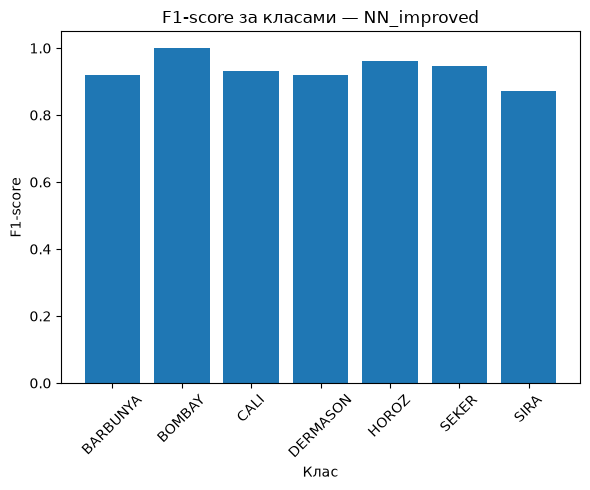

In [43]:
class_report = classification_report(
    y_test_encoded,
    best_nn_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

f1_by_class = {
    class_name: class_report[class_name]["f1-score"]
    for class_name in class_names
}

plt.figure(figsize=(6, 5))

plt.bar(
    f1_by_class.keys(),
    f1_by_class.values()
)

plt.title(f"F1-score за класами — {best_nn_name}")
plt.xlabel("Клас")
plt.ylabel("F1-score")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "04_f1_by_class.png", dpi=300)

plt.show()

## Аналіз найбільш упевнених неправильних передбачень ##

In [44]:
best_nn_probabilities = test_probabilities[best_nn_name]

wrong_mask = best_nn_predictions != y_test_encoded

wrong_indices = np.where(wrong_mask)[0]

wrong_confidence = best_nn_probabilities[wrong_indices].max(axis=1)

sorted_wrong = wrong_indices[
    np.argsort(wrong_confidence)[::-1]
]

top_wrong = sorted_wrong[:5]

for i in top_wrong:

    print("\nІстинний клас:", class_names[y_test_encoded[i]])
    print("Передбачений клас:", class_names[best_nn_predictions[i]])
    print("Упевненість:", best_nn_probabilities[i].max())

    print("\nЙмовірності класів:")
    print(dict(zip(class_names, best_nn_probabilities[i])))

    print("\nОзнаки об'єкта:")
    display(X_test.iloc[i].to_frame().T)


Істинний клас: SEKER
Передбачений клас: SIRA
Упевненість: 0.99820364

Ймовірності класів:
{'BARBUNYA': np.float32(0.00011198749), 'BOMBAY': np.float32(3.547908e-11), 'CALI': np.float32(0.0004185692), 'DERMASON': np.float32(6.1961546e-05), 'HOROZ': np.float32(0.000115963376), 'SEKER': np.float32(0.0010877748), 'SIRA': np.float32(0.99820364)}

Ознаки об'єкта:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
1844,46427.0,811.657,293.918029,202.24616,1.453269,0.725612,46974.0,243.131019,0.683796,0.988355,0.885596,0.827207,0.006331,0.001828,0.684271,0.99443



Істинний клас: BARBUNYA
Передбачений клас: SIRA
Упевненість: 0.99475867

Ймовірності класів:
{'BARBUNYA': np.float32(0.00216567), 'BOMBAY': np.float32(3.095224e-10), 'CALI': np.float32(0.0024110368), 'DERMASON': np.float32(6.6576475e-05), 'HOROZ': np.float32(0.0002645257), 'SEKER': np.float32(0.00033353132), 'SIRA': np.float32(0.99475867)}

Ознаки об'єкта:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
2048,48160.0,829.234,304.528282,202.715513,1.502245,0.746246,48950.0,247.627172,0.754043,0.983861,0.880121,0.81315,0.006323,0.001705,0.661213,0.993304



Істинний клас: CALI
Передбачений клас: SEKER
Упевненість: 0.9947397

Ймовірності класів:
{'BARBUNYA': np.float32(0.0018726101), 'BOMBAY': np.float32(7.2568227e-09), 'CALI': np.float32(0.00044022937), 'DERMASON': np.float32(4.1589137e-05), 'HOROZ': np.float32(1.3180136e-05), 'SEKER': np.float32(0.9947397), 'SIRA': np.float32(0.002892716)}

Ознаки об'єкта:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
3872,45666.0,789.77,274.863357,211.885139,1.297228,0.636987,46074.0,241.130166,0.748378,0.991145,0.920029,0.877273,0.006019,0.002199,0.769608,0.998357



Істинний клас: SIRA
Передбачений клас: DERMASON
Упевненість: 0.9922806

Ймовірності класів:
{'BARBUNYA': np.float32(2.5089793e-08), 'BOMBAY': np.float32(1.9935147e-12), 'CALI': np.float32(2.6105e-07), 'DERMASON': np.float32(0.9922806), 'HOROZ': np.float32(0.0010020789), 'SEKER': np.float32(0.00023359626), 'SIRA': np.float32(0.006483431)}

Ознаки об'єкта:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
7415,35827.0,703.778,269.608418,169.491924,1.590686,0.777681,36164.0,213.579852,0.74035,0.990681,0.908969,0.792185,0.007525,0.001828,0.627558,0.998247



Істинний клас: SIRA
Передбачений клас: BARBUNYA
Упевненість: 0.99224275

Ймовірності класів:
{'BARBUNYA': np.float32(0.99224275), 'BOMBAY': np.float32(1.5083393e-11), 'CALI': np.float32(0.0015699499), 'DERMASON': np.float32(1.2002153e-06), 'HOROZ': np.float32(0.0023849846), 'SEKER': np.float32(0.0003025553), 'SIRA': np.float32(0.0034985996)}

Ознаки об'єкта:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
9763,50976.0,932.171,327.642954,199.214434,1.644675,0.793919,52067.0,254.763928,0.792168,0.979046,0.737198,0.777566,0.006427,0.001449,0.604608,0.994384


## Збереження моделі та перевірка відтворюваності ##

In [45]:
best_nn.save(ARTIFACTS_DIR / "lab8_model.keras")
print("Найкращу нейронну мережу збережено.")

if best_model_name == "LogisticRegression":
    dump(
        logreg_model,
        ARTIFACTS_DIR / "logistic_regression.joblib"
    )
    print("Logistic Regression збережено.")

dump(
    preprocessor,
    ARTIFACTS_DIR / "preprocessor.joblib"
)
print("Preprocessor збережено.")    

metadata = {
    "dataset": "Dry Bean Dataset",
    "source": dataset_info["url"],
    "file": dataset_info["file"],
    "sheet": dataset_info["sheet"],
    "target": "Class",
    "target_units": dataset_info["target_units"],
    "task": "Multiclass classification",
    "features": X.columns.tolist(),
    "class_order": class_names.tolist(),
    "positive_class": None,
    "seed": SEED,
    "split_indices": split_indices,
    "best_model": best_model_name,
    "best_neural_network": best_nn_name,
    "tested_change": "Learning rate 0.001 -> 0.0003",
    "best_nn_epoch": int(best_nn_epoch),
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "tensorflow": tf.__version__
    }
}

with open(
    ARTIFACTS_DIR / "metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print("Metadata збережено.")


loaded_model = keras.models.load_model(
    ARTIFACTS_DIR / "lab8_model.keras"
)

loaded_preprocessor = load(
    ARTIFACTS_DIR / "preprocessor.joblib"
)
print("Модель та обробник успішно завантажено.")



Найкращу нейронну мережу збережено.
Preprocessor збережено.
Metadata збережено.
Модель та обробник успішно завантажено.


## Перевірка однаковості прогнозів до та після завантаження ##

In [46]:
raw_samples = X_test.iloc[:3]

before = best_nn.predict(
    preprocessor.transform(raw_samples).astype(np.float32),
    verbose=0
)

after = loaded_model.predict(
    loaded_preprocessor.transform(raw_samples).astype(np.float32),
    verbose=0
)

np.testing.assert_allclose(
    before,
    after,
    rtol=1e-5,
    atol=1e-6
)

print("Перевірку відтворюваності успішно пройдено.")

Перевірку відтворюваності успішно пройдено.


## Створення README.md ##

In [47]:
readme = f"""
# Lab 8 — Dry Bean Dataset

## Dataset
Dry Bean Dataset from UCI Machine Learning Repository.

## Task
Multiclass classification of seven varieties of dry beans.

## Reproduction
1. Install the required Python libraries.
2. Place Dry_Bean_Dataset.xlsx into the data folder.
3. Run all notebook cells sequentially.

## Random seed
{SEED}

## Best model
{best_model_name}

## Best neural network
{best_nn_name}
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md створено.")

README.md створено.
